# Wordle strategy explorer

Explore an **optimal tree** — the committed per-opener strategy the solver emits — as a
table of *positions*. Pick an `OPENER` and the cells below enumerate every situation that
strategy can reach: the guesses played so far, the feedback each one got, how many answers
are still possible, and the optimal next guess.

Modelled on `hangman/math/notebooks/strategy_explorer.ipynb` ("All situations at depth k",
"Inspect a tree node"), over Wordle's tree files instead of hangman's.

**Where the data comes from.** `paths.TREES` resolves to the tree directory this machine
should read (the live `local/<solver>/trees/` on a sweep machine, else the committed
`shared/<solver>/trees/`). One gzipped file per opener, one line per answer:

```
nymph 3 salet bbbbb courd bbbbb nymph
```

— the answer, its guess count, then `guess pattern guess pattern ... guess`. There are N
guesses and N-1 patterns, because the last guess *is* the answer and its feedback is
all-green by construction. A pattern is a 5-character string: **`b`** = grey, **`y`** =
yellow, **`g`** = green.

Setting `WORDLE_SOLVER=hardturns` (or `ansturns`) before starting the kernel points every
cell at that sweep instead.

> **The objective these trees optimise is CONSTRAINED.** Each tree minimises the TOTAL
> guesses over the 2315 answers *subject to resolving every answer within `--depth`*. That
> is not the same as minimum expected guesses, and anything read off these positions
> inherits that constraint.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'wordle.py').exists():
            return c
    raise FileNotFoundError('Could not find wordle.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
for p in (math_dir, math_dir / 'tools'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import wordle                     # the feedback primitives (math/wordle.py)
import paths                      # the canonical solver locations (math/tools/paths.py)
import tiers                      # the video's letter tier list (math/tiers.py)

pd.set_option('display.max_rows', 200)   # show up to 200 rows before pandas truncates to a head/tail preview

print(f'imported wordle + paths from {math_dir}')
print(f'solver = {paths.SOLVER!r}')
print(f'trees  = {paths.TREES}')

imported wordle + paths from /Users/patrickliscio/Documents/Ballpark Figures/ballpark-figures/wordle/math
solver = 'optturns'
trees  = /Users/patrickliscio/Documents/Ballpark Figures/ballpark-figures/wordle/math/data/shared/optturns/trees


## Pick an opener

`OPENER` is any word with a committed tree. The totals come from the sweep's
`opener_totals.csv`: `total` is the summed guesses over all 2315 answers.

In [2]:
OPENER = 'salet'    # <-- the opener whose optimal tree to explore

_totals = paths.load_totals()
_tree_path = Path(paths.TREES) / f'{OPENER}.txt.gz'

print(f'{OPENER!r}: tree {"found" if _tree_path.exists() else "MISSING"} at {_tree_path}')
if OPENER in _totals:
    print(f'  total {_totals[OPENER]:,} guesses over {paths.N_ANSWERS:,} answers'
          f'  ({_totals[OPENER] / paths.N_ANSWERS:.5f} per answer)')
else:
    print(f'  no row in {paths.CSV_PATH} -- not solved (or INFEASIBLE) in this sweep')

'salet': tree found at /Users/patrickliscio/Documents/Ballpark Figures/ballpark-figures/wordle/math/data/shared/optturns/trees/salet.txt.gz
  total 7,920 guesses over 2,315 answers  (3.42117 per answer)


## Every position in the tree

`positions(opener)` returns one row per **position**: a distinct history of
(guess, feedback) pairs the strategy can reach.

| column | meaning |
| --- | --- |
| `depth` | guesses already played (0 = the root, before the opener) |
| `guesses` | those guesses, in order, space separated |
| `patterns` | the feedback each one got, space separated `byg` strings |
| `n_answers` | answers still possible at this position |
| `guess` | the **optimal next guess** — the tree's move here |
| `solved` | one answer left, so `guess` just plays it |
| `sample` | a few of the possible answers, for identification |

**How it is derived.** Every answer's line records the full path the strategy walks for
that answer, so taking each *prefix* of its (guess, pattern) pairs enumerates the positions
that answer passes through. Answers sharing a prefix are exactly the answers still
consistent with that history — the strategy is deterministic, so two answers part company
only where their feedback differs — which is why counting the lines through a node gives
its candidate count. The last row of a path is the position where one answer remains and
`guess` is that answer.

In [3]:
def read_tree(opener, trees=None):
    """Parse one committed tree; yield (answer, n_guesses, guesses, patterns) per answer.

    `guesses` has n entries and `patterns` has n-1: the final guess is the answer
    itself and carries no pattern (its feedback is all-green by construction)."""
    path = Path(trees or paths.TREES) / f'{opener}.txt.gz'
    if not path.exists():
        raise FileNotFoundError(f'no tree for {opener!r} at {path}')
    with gzip.open(path, 'rt') as f:
        for line in f:
            parts = line.split()
            if not parts:
                continue
            yield parts[0], int(parts[1]), parts[2::2], parts[3::2]


def positions(opener, trees=None, sample=4):
    """Every position reachable under `opener`'s optimal tree, as a DataFrame.

    One row per distinct (guesses so far, patterns so far) history -- see the
    markdown above for the columns and how the counts are derived. `sample` caps
    how many possible answers each row lists."""
    nodes = {}
    for answer, n, guesses, pats in read_tree(opener, trees):
        for k in range(len(guesses)):            # k pairs played, guesses[k] is next
            key = tuple(zip(guesses[:k], pats[:k]))
            node = nodes.get(key)
            if node is None:
                nodes[key] = node = {'guess': guesses[k], 'answers': []}
            elif node['guess'] != guesses[k]:
                # A tree is a deterministic strategy: one move per position. Two
                # different moves after the same history means it is not one.
                raise ValueError(f'{opener}: position {key} has two moves, '
                                 f'{node["guess"]!r} and {guesses[k]!r}')
            node['answers'].append(answer)

    rows = []
    for key, node in nodes.items():
        answers = node['answers']
        rows.append({
            'depth': len(key),
            'guesses': ' '.join(g for g, _ in key),
            'patterns': ' '.join(p for _, p in key),
            'n_answers': len(answers),
            'guess': node['guess'],
            'solved': len(answers) == 1,
            'sample': ' '.join(sorted(answers)[:sample]),
        })
    return (pd.DataFrame(rows)
              .sort_values(['depth', 'n_answers', 'guesses'], ascending=[True, False, True])
              .reset_index(drop=True))


pos = positions(OPENER)
print(f'{OPENER!r}: {len(pos):,} positions, depth {pos["depth"].min()}-{pos["depth"].max()}')
display(pos.head(50))

'salet': 2,391 positions, depth 0-4


,depth,guesses,patterns,n_answers,guess,solved,sample
0,0,,,2315,salet,False,aback abase abate abbey
1,1,salet,bbbbb,221,courd,False,biddy bingo birch bobby
2,1,salet,bbbyb,165,drone,False,beech beefy begin begun
3,1,salet,bbbgb,107,rownd,False,bicep boney boxer breed
4,1,salet,bybbb,102,brond,False,aback abhor acorn acrid
5,1,salet,bbybb,99,courd,False,blimp blind blink block
6,1,salet,bbbby,86,north,False,birth bitty booth booty
7,1,salet,bybyb,83,beard,False,abide abode above adage
8,1,salet,bgbbb,82,corny,False,bacon baggy banjo baron
9,1,salet,byybb,67,corni,False,afoul alarm album alibi


## Positions at one depth

`DEPTH` guesses are already in, and `guess` is the next one. `DEPTH = 0` is the root — one
position, the empty history, whose move is the opener itself.

In [4]:
DEPTH = 1      # <-- guesses already played

at = pos[pos['depth'] == DEPTH]
live = at[~at['solved']]
print(f'depth {DEPTH}: {len(at):,} positions, {len(live):,} of them with more than one '
      f'answer left, covering {at["n_answers"].sum():,} answers')
display(at.head(50).reset_index(drop=True))

depth 1: 148 positions, 114 of them with more than one answer left, covering 2,315 answers


,depth,guesses,patterns,n_answers,guess,solved,sample
0,1,salet,bbbbb,221,courd,False,biddy bingo birch bobby
1,1,salet,bbbyb,165,drone,False,beech beefy begin begun
2,1,salet,bbbgb,107,rownd,False,bicep boney boxer breed
3,1,salet,bybbb,102,brond,False,aback abhor acorn acrid
4,1,salet,bbybb,99,courd,False,blimp blind blink block
5,1,salet,bbbby,86,north,False,birth bitty booth booty
6,1,salet,bybyb,83,beard,False,abide abode above adage
7,1,salet,bgbbb,82,corny,False,bacon baggy banjo baron
8,1,salet,byybb,67,corni,False,afoul alarm album alibi
9,1,salet,gbbbb,56,unrip,False,scion scoff scoop scorn


### ...grouped by the next guess

The same depth-`DEPTH` positions, collapsed onto the optimal next guess: `n_answers` is the
total answers that guess is played against across every position it serves, `n_patterns` is
how many distinct feedback histories lead to it, and `patterns` lists them (in the same
descending-`n_answers` order as the table above, `|`-separated once a history is more than
one pattern long). Sorted by `n_answers` descending.

In [5]:
by_guess = (at.groupby('guess', sort=False)
              .agg(n_answers=('n_answers', 'sum'),
                   n_patterns=('patterns', 'size'),
                   patterns=('patterns', ' | '.join))
              .sort_values('n_answers', ascending=False)
              .reset_index())

print(f'depth {DEPTH}: {len(by_guess):,} distinct next guesses over {len(at):,} positions')
display(by_guess)

depth 1: 145 distinct next guesses over 148 positions


,guess,n_answers,n_patterns,patterns
0,courd,340,3,bbbbb | bbybb | bybbg
1,drone,165,1,bbbyb
2,rownd,107,1,bbbgb
3,brond,102,1,bybbb
4,north,86,1,bbbby
5,beard,83,1,bybyb
6,corny,82,1,bgbbb
7,corni,67,1,byybb
8,unrip,56,1,gbbbb
9,trite,52,1,bbbyy


### Letter frequencies among those guesses

Every letter appearing in the depth-`DEPTH` next guesses, weighted by `n_answers` — a
letter's `n_answers` is the total answers sitting in the positions whose guess contains it,
so a guess played against 340 answers counts 340 times more than one played against 1.
`share` is that against all answers at this depth; it sums to well over 1, since each
position contributes its answers to five letters at once.

`LIVE_ONLY` drops positions already down to a single answer (where `guess` is just that
answer being played) so only real decisions count. `COUNT_REPEATS` decides whether a
doubled letter counts twice in its word.

Both knobs set `words`, the frame this cell and the next one work from.

depth 1: 23 distinct letters over 148 positions (2,315 answers)


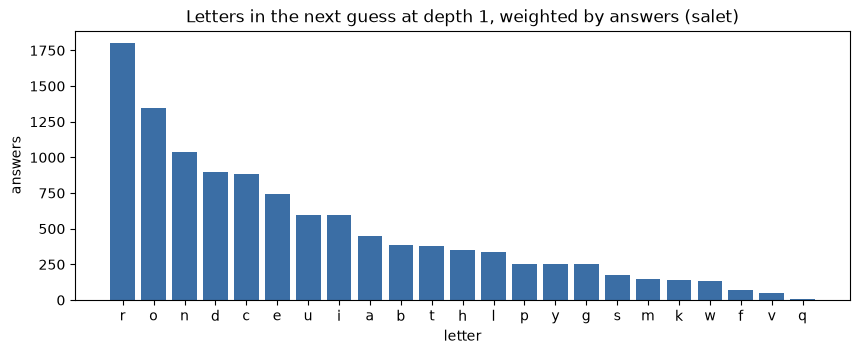

,letter,n_answers,n_positions,n_guesses,share
0,r,1799,56,53,0.777106
1,o,1345,35,33,0.580994
2,n,1038,30,29,0.448380
3,d,896,19,17,0.387041
4,c,884,33,31,0.381857
5,e,745,75,75,0.321814
6,u,599,20,18,0.258747
7,i,594,38,37,0.256587
8,a,451,70,70,0.194816
9,b,386,19,19,0.166739


In [6]:
import string

LIVE_ONLY    = False   # <-- True: ignore positions with one answer left (guess = that answer)
COUNT_REPEATS = False  # <-- True: 'abbey' counts b twice; False: each letter once per word

words = at[~at['solved']] if LIVE_ONLY else at
_total = words['n_answers'].sum()

rows = []
for letter in string.ascii_lowercase:
    hits = words['guess'].apply(lambda w: w.count(letter) if COUNT_REPEATS else int(letter in w))
    if not hits.any():
        continue
    rows.append({'letter': letter,
                 'n_answers': int((hits * words['n_answers']).sum()),
                 'n_positions': int((hits > 0).sum()),
                 'n_guesses': words.loc[hits > 0, 'guess'].nunique()})

letter_freq = (pd.DataFrame(rows)
                 .assign(share=lambda d: d['n_answers'] / _total)
                 .sort_values('n_answers', ascending=False)
                 .reset_index(drop=True))

print(f'depth {DEPTH}: {len(letter_freq)} distinct letters over {len(words):,} positions '
      f'({_total:,} answers){" -- live positions only" if LIVE_ONLY else ""}')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(letter_freq['letter'], letter_freq['n_answers'], color='#3b6ea5')
ax.set_ylabel('answers'); ax.set_xlabel('letter')
ax.set_title(f'Letters in the next guess at depth {DEPTH}, weighted by answers ({OPENER})')
plt.show()
display(letter_freq)

### How many letters are new

A guess's **new letters** are the distinct letters in it that none of the previous guesses
carried — how much fresh alphabet the strategy buys at this position, from 0 (every letter
already played) to 5. At `DEPTH = 0` there is no history, so it is just the opener's
distinct-letter count.

The table is the distribution over the same `words` frame: how many positions land on each
count, and how many answers they cover between them.

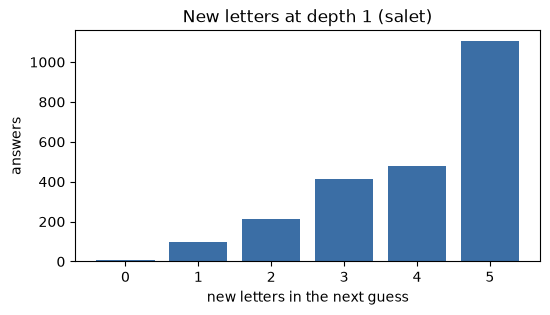

,new_letters,n_positions,n_answers,share
0,0,7,9,0.003888
1,1,37,98,0.042333
2,2,43,212,0.091577
3,3,24,415,0.179266
4,4,13,478,0.206479
5,5,24,1103,0.476458


positions with the fewest new letters:


,guesses,patterns,n_answers,guess,new_letters
0,salet,gyyyy,3,slate,0
1,salet,yybyy,1,tease,0
2,salet,yybgg,1,asset,0
3,salet,yyyyg,1,least,0
4,salet,ygygb,1,easel,0
5,salet,gbygy,1,steel,0
6,salet,gbygg,1,sleet,0
7,salet,bygbb,11,allay,1
8,salet,byyyg,8,leapt,1
9,salet,bbyyy,7,title,1


In [7]:
seen = words['guesses'].apply(lambda h: set(h.replace(' ', '')))
newness = words.assign(new_letters=[len(set(g) - h) for g, h in zip(words['guess'], seen)])

new_dist = (newness.groupby('new_letters')
                   .agg(n_positions=('guess', 'size'), n_answers=('n_answers', 'sum'))
                   .assign(share=lambda d: d['n_answers'] / d['n_answers'].sum())
                   .reset_index())

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(new_dist['new_letters'], new_dist['n_answers'], color='#3b6ea5')
ax.set_xlabel('new letters in the next guess'); ax.set_ylabel('answers')
ax.set_xticks(range(0, 6))
ax.set_title(f'New letters at depth {DEPTH} ({OPENER})')
plt.show()
display(new_dist)

print('positions with the fewest new letters:')
display(newness.sort_values(['new_letters', 'n_answers'], ascending=[True, False])
               .head(15)[['guesses', 'patterns', 'n_answers', 'guess', 'new_letters']]
               .reset_index(drop=True))

## Look up one position

Filter by the history you have in hand — it is just a prefix of the `guesses`/`patterns`
columns. The second table is every outcome the optimal next guess can produce from there.

In [8]:
HISTORY  = 'salet'     # <-- guesses so far, space separated ('' for the root)
FEEDBACK = 'bbbyb'     # <-- their feedback, space separated `byg` strings ('' for the root)

hit = pos[(pos['guesses'] == HISTORY) & (pos['patterns'] == FEEDBACK)]
if hit.empty:
    print(f'no position with guesses {HISTORY!r} and patterns {FEEDBACK!r} in '
          f'{OPENER!r}\'s tree -- unreachable under this strategy, or a typo')
else:
    r = hit.iloc[0]
    print(f'{r["n_answers"]:,} answers left; optimal next guess: {r["guess"]!r}')
    display(hit)
    kids = pos[pos['guesses'] == (HISTORY + ' ' + r['guess']).strip()]
    print(f'{len(kids)} outcome(s) of {r["guess"]!r} here:')
    display(kids.reset_index(drop=True))

165 answers left; optimal next guess: 'drone'


,depth,guesses,patterns,n_answers,guess,solved,sample
2,1,salet,bbbyb,165,drone,False,beech beefy begin begun


57 outcome(s) of 'drone' here:


,depth,guesses,patterns,n_answers,guess,solved,sample
0,2,salet drone,bbbyb bbbyg,12,finch,False,binge fence genie hence
1,2,salet drone,bbbyb bybby,12,femur,False,berry every femur ferry
2,2,salet drone,bbbyb bybbg,10,merge,False,curve eerie fibre merge
3,2,salet drone,bbbyb bbbbg,9,piece,False,chime femme fugue imbue
4,2,salet drone,bbbyb bgbbg,9,campi,False,bribe creme crepe crime
5,2,salet drone,bbbyb bbbyy,8,begin,False,begin begun bench enemy
6,2,salet drone,bbbyb ybbbg,8,bijou,False,budge chide fudge guide
7,2,salet drone,bbbyb bbbby,6,beech,False,beech beefy check equip
8,2,salet drone,bbbyb byybg,6,forge,False,force forge gorge ombre
9,2,salet drone,bbbyb bggbg,6,probe,False,broke froze grope grove


## Cross-check the counts

`n_answers` is read off the tree's structure (lines sharing a prefix). This re-derives it
from scratch for a random sample of positions — filtering the 2315 answers by replaying
each guess/feedback pair through `wordle.pattern` — so a misparse shows up as a mismatch
rather than as a plausible-looking wrong number. Same spirit as `tools/checktrees.py`.

In [9]:
N_CHECK = 200      # <-- how many random positions to re-derive

_answers = wordle.load_words('mystery')
_tiles = {'b': 0, 'y': 1, 'g': 2}

def answers_after(guesses, patterns):
    """The answers consistent with a history, from the feedback function alone."""
    alive = list(_answers)
    for g, p in zip(guesses, patterns):
        want = sum(_tiles[c] * 3 ** (wordle.WORD_LEN - 1 - i) for i, c in enumerate(p))
        alive = [a for a in alive if wordle.pattern(g, a) == want]
    return alive

rng = np.random.default_rng(0)                       # reproducible sample
idx = rng.choice(len(pos), size=min(N_CHECK, len(pos)), replace=False)
bad = []
for i in idx:
    r = pos.iloc[int(i)]
    n = len(answers_after(r['guesses'].split(), r['patterns'].split()))
    if n != r['n_answers']:
        bad.append((r['guesses'], r['patterns'], r['n_answers'], n))

print(f'checked {len(idx)} positions of {OPENER!r}: '
      + ('all counts agree' if not bad else f'{len(bad)} MISMATCH(ES)'))
for g, p, tree_n, real_n in bad[:10]:
    print(f'  {g} | {p}: table says {tree_n}, filter says {real_n}')

checked 200 positions of 'salet': all counts agree


## Every opener's average — the distribution

The cells above walk ONE opener's tree. This section steps back to the whole sweep: the
committed `opener_totals.csv` already holds every opener's optimal `total`, so the
distribution over all 12,972 of them is a read, not a computation.

**The x axis is the average guesses per answer, in bins of 0.01.** That average is `total`
over the 2,315 answers — the objective is an integer total, and this is it per answer, the
same figure the single-opener cell above prints. Every opener lands between 3.42 and 4.10,
so 0.01 gives about 68 bins; the same 0.01-bin convention `tools/report.py` uses for the
standing histogram. The top axis carries the same scale read as the raw total.

> **These are CONSTRAINED optima.** Each `total` is the minimum SUBJECT TO resolving every
> answer within `--depth` (6 in the normal sweep) — not a minimum expected guess count.
> Whether the cap binds is an open question, so never table these against an
> unconstrained expected-guesses number (`topk.py`'s 3.9782, a `wordlesim` mean).

In [10]:
_answer_words = set(wordle.load_words('mystery'))
VOWELS = 'aeiouy'        # <-- Y ALWAYS COUNTS as a vowel here (the user's call)

def opener_frame():
    """One row per SOLVED opener, plus the word features the conditions filter on.

    `total` comes from the sweep's CSV via `paths.load_totals()` (which dedups
    across any archived runs and skips INFEASIBLE rows); `expected` is that over
    the answer count -- the same total / N_ANSWERS the single-opener cell above
    prints. Nothing is re-solved here: both numbers are the committed result."""
    totals = paths.load_totals()
    df = pd.DataFrame({'word': list(totals), 'total': list(totals.values())})
    df['expected']   = df['total'] / paths.N_ANSWERS
    df['letters']    = df['word'].apply(frozenset)      # the SET, so repeats collapse
    df['n_distinct'] = df['letters'].apply(len)
    df['n_dup']      = wordle.WORD_LEN - df['n_distinct']   # duplicate TILES: 'abbey' -> 1
    df['n_vowels']   = df['letters'].apply(lambda s: len(s & set(VOWELS)))  # DISTINCT
    df['is_answer']  = df['word'].isin(_answer_words)
    return df.sort_values('total').reset_index(drop=True)


openers = opener_frame()
_infeasible = paths.load_infeasible()
_unsolved = paths.N_GUESSES - len(openers) - len(_infeasible)

print(f'{len(openers):,} solved openers of {paths.N_GUESSES:,}'
      + (f', {len(_infeasible):,} INFEASIBLE' if _infeasible else '')
      + (f', {_unsolved:,} not yet solved' if _unsolved else ''))
print(f'total    {openers["total"].min():,} .. {openers["total"].max():,}'
      f'  ({openers["total"].max() - openers["total"].min():,} guesses apart)')
print(f'expected {openers["expected"].min():.5f} .. {openers["expected"].max():.5f} per answer')
display(openers.head(5))

12,972 solved openers of 12,972
total    7,920 .. 9,496  (1,576 guesses apart)
expected 3.42117 .. 4.10194 per answer


,word,total,expected,letters,n_distinct,n_vowels,is_answer
0,salet,7920,3.421166,"frozenset({a, l, e, t, s})",5,2,False
1,reast,7923,3.422462,"frozenset({r, a, e, t, s})",5,2,False
2,crate,7926,3.423758,"frozenset({r, a, c, e, t})",5,2,True
3,trace,7926,3.423758,"frozenset({r, a, c, e, t})",5,2,True
4,slate,7928,3.424622,"frozenset({a, l, e, t, s})",5,2,True


### The histogram, and sub-histograms under a condition

`plot_openers(condition, label=...)` draws the full distribution faintly and the openers
satisfying `condition` on top of it, so the subset reads as the part of the whole it is —
the same overlay the yahtzee score-distribution cells use.

- `condition` is a boolean Series over `openers`; the helpers below build them and `&`,
  `|`, `~` combine them.
- `width` is in average guesses (`BIN`, default 0.01); `start`/`end` clip the x range.

Both series are counts over the same bins, so the subset always sits inside the field.

**`plot_nested([(cond, label), ...])` goes further: sub-sub-histograms.** Each layer is
drawn on top of the one before it, outermost first — "1+ from the bottom tier", then "2+"
inside it, and so on. Every layer must be **strictly contained** in the one before, and
that is CHECKED rather than assumed: a layer holding an opener its parent lacks raises,
naming the word, since the nested picture would otherwise be a lie. Layers darken as they
narrow.

Each call also prints every layer's mean, median, best and worst against the same figures
for the whole field, since a mean shift is easier to read off a number than off a bar.

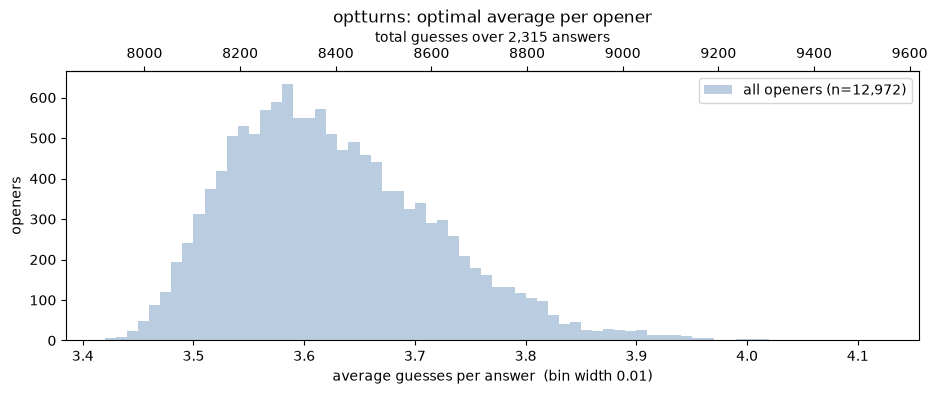

all openers  n=12,972  mean 3.6259  median 3.6138  best salet 3.4212  worst qajaq 4.1019


In [11]:
BIN = 0.01     # <-- bin width, in AVERAGE guesses per answer

# Layers darken as they narrow; the field underneath them is the same faint blue.
FIELD_COLOR = '#3b6ea5'
LAYER_COLORS = ('#e9a05a', '#c1662f', '#8c3b1e', '#5a1f10')


def _edges(width, start=None, end=None):
    """Bin edges aligned to multiples of `width`, covering the whole range.

    Built by an integer step count rather than np.arange on floats, so a width
    like 0.01 cannot accumulate its way to a missing final bin."""
    lo = openers['expected'].min() if start is None else start
    hi = openers['expected'].max() if end is None else end
    lo = np.floor(lo / width) * width
    n = int(np.ceil((hi - lo) / width)) + 1
    return lo + width * np.arange(n + 1)


def _describe(name, d, pad):
    if d.empty:
        return f'{name:>{pad}}  n=     0  (no openers satisfy it)'
    best, worst = d['total'].idxmin(), d['total'].idxmax()
    return (f'{name:>{pad}}  n={len(d):>6,}  mean {d["expected"].mean():.4f}  '
            f'median {d["expected"].median():.4f}  '
            f'best {d.loc[best, "word"]} {d.loc[best, "expected"]:.4f}  '
            f'worst {d.loc[worst, "word"]} {d.loc[worst, "expected"]:.4f}')


def _check_nested(layers):
    """Each layer must be a subset of the one before it -- raise if it is not.

    The whole point of the picture is that a layer is PART of the layer under it,
    so a stray opener would draw a bar taller than its parent's and read as a
    contradiction. Cheap to check, so it is never assumed."""
    for (outer, outer_label), (inner, inner_label) in zip(layers, layers[1:]):
        stray = openers[inner & ~outer]
        if len(stray):
            raise ValueError(
                f'{inner_label!r} is not contained in {outer_label!r}: '
                f'{len(stray)} opener(s) outside it, e.g. '
                + ', '.join(stray['word'].head(3)))


def plot_nested(layers, width=BIN, start=None, end=None, colors=LAYER_COLORS, ax=None):
    """The field, plus each of `layers` drawn on top of the one before it.

    `layers` is [(condition, label), ...] ordered OUTERMOST FIRST, each strictly
    contained in the one before -- which is checked, not assumed. Every series is
    a count of openers over the same bins, so each sits inside its parent."""
    layers = list(layers)
    _check_nested(layers)
    edges = _edges(width, start, end)
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3.5))

    ax.hist(openers['expected'], bins=edges, color=FIELD_COLOR, alpha=0.35,
            label=f'all openers (n={len(openers):,})')
    for i, (cond, label) in enumerate(layers):
        sub = openers[cond]
        if len(sub):
            ax.hist(sub['expected'], bins=edges, color=colors[i % len(colors)],
                    alpha=0.85, label=f'{label} (n={len(sub):,})')

    n = paths.N_ANSWERS
    top = ax.secondary_xaxis('top', functions=(lambda e: e * n, lambda t: t / n))
    top.set_xlabel(f'total guesses over {n:,} answers')
    ax.set_xlabel(f'average guesses per answer  (bin width {width:g})')
    ax.set_ylabel('openers')
    ax.set_title(f'{paths.SOLVER}: optimal average per opener'
                 + (f' — {layers[0][1]}' if layers else ''))
    ax.legend()
    plt.show()

    pad = max([len('all openers')] + [len(l) for _, l in layers])
    print(_describe('all openers', openers, pad))
    prev = None
    for cond, label in layers:
        sub = openers[cond]
        print(_describe(label, sub, pad))
        if len(sub):
            of_parent = ('' if prev is None else
                         f', {100 * len(sub) / len(prev):.1f}% of the layer above')
            print(f'{"":>{pad}}  {100 * len(sub) / len(openers):.2f}% of the field'
                  f'{of_parent}, mean '
                  f'{sub["expected"].mean() - openers["expected"].mean():+.4f} against it')
        prev = sub


def plot_openers(condition=None, label='condition', **kw):
    """One condition against the field -- `plot_nested` with a single layer."""
    return plot_nested([] if condition is None else [(condition, label)], **kw)


plot_openers()

### Building a condition

Each helper returns a boolean Series over `openers`, so they combine with `&`, `|` and `~`:

| helper | openers it selects |
| --- | --- |
| `has_any('sr')` | containing **at least one** of those letters |
| `has_all('sr')` | containing **all** of them |
| `has_none('sr')` | containing **none** of them |
| `count_of('sr')` | how many of the five TILES are one of them (so a repeat counts twice) — compare it, e.g. `count_of(tiers.bottom(1)) >= 2` |
| `at(0, 'st')` | whose position `0` (0-based) holds one of those letters |
| `matches('s...e')` | whose word fully matches a regex |
| `has_repeat` | with a doubled (or tripled) letter |
| `openers['n_dup'] >= 2` | with at least that many duplicate TILES (`5 - n_distinct`) |
| `openers['n_vowels'] >= 3` | with at least that many DISTINCT vowels, `aeiouy` |
| `openers['is_answer']` | that are one of the 2,315 mystery words |

`has_any`/`has_all`/`has_none` take any iterable of letters — a string or a `tiers.bottom(n)`
set. They work on the letter SET, so `'abbey'` is treated the same as any other b-word; use
`count_of` when the number of tiles matters.

In [12]:
def has_any(letters):
    """Openers containing at least one of `letters` ('sr', or any iterable)."""
    s = set(letters)
    return openers['letters'].apply(lambda w: bool(w & s))


def has_all(letters):
    """Openers containing every one of `letters`."""
    s = set(letters)
    return openers['letters'].apply(lambda w: s <= w)


def has_none(letters):
    """Openers containing none of `letters`."""
    s = set(letters)
    return openers['letters'].apply(lambda w: not (w & s))


def count_of(letters):
    """How many of the five TILES are one of `letters` -- a repeat counts twice."""
    s = set(letters)
    return openers['word'].apply(lambda w: sum(c in s for c in w))


def at(i, letters):
    """Openers whose position `i` (0-based) holds one of `letters`."""
    return openers['word'].str[i].isin(set(letters))


def matches(regex):
    """Openers whose word fully matches `regex`, e.g. matches('s...e')."""
    return openers['word'].str.fullmatch(regex)


has_repeat = openers['n_distinct'] < 5      # a doubled (or tripled) letter

print('helpers ready:', ', '.join(['has_any', 'has_all', 'has_none', 'count_of',
                                   'at', 'matches', 'has_repeat']))

helpers ready: has_any, has_all, has_none, count_of, at, matches, has_repeat


### Sub-histograms

One condition per cell, so each stays a knob to edit. Copy a cell and change the condition.

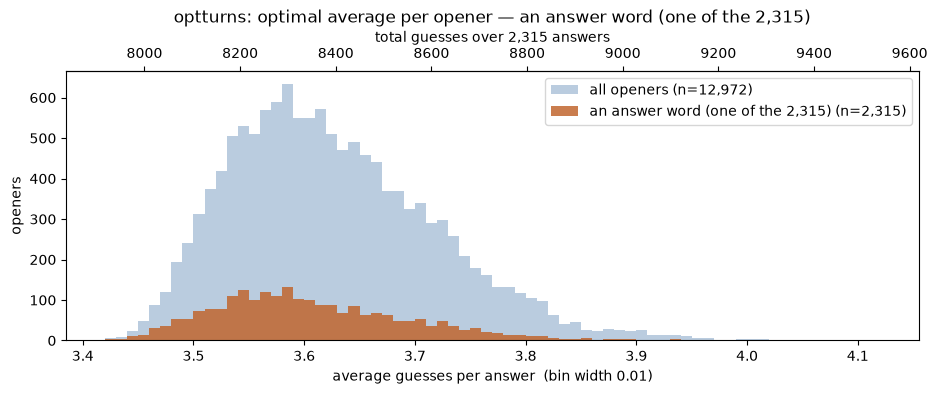

                      all openers  n=12,972  mean 3.6259  median 3.6138  best salet 3.4212  worst qajaq 4.1019
an answer word (one of the 2,315)  n= 2,315  mean 3.6073  median 3.5922  best crate 3.4238  worst jazzy 4.0164
                                   17.85% of the field, mean -0.0186 guesses against it


In [16]:
plot_openers(openers['is_answer'], label='an answer word (one of the 2,315)')

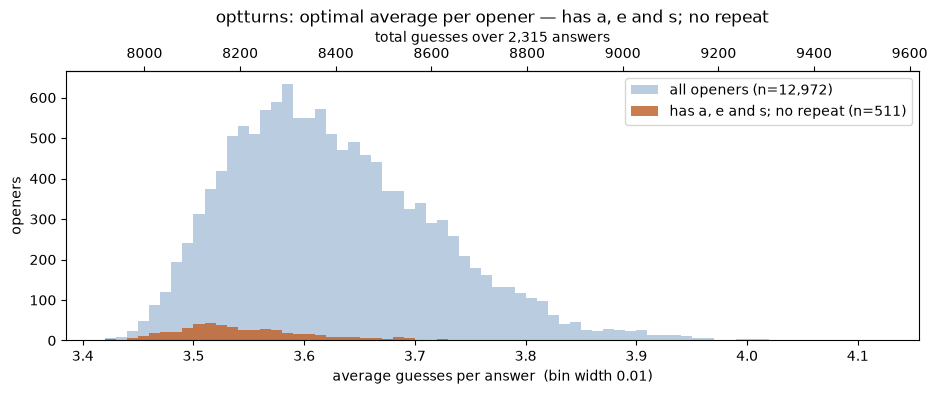

              all openers  n=12,972  mean 3.6259  median 3.6138  best salet 3.4212  worst qajaq 4.1019
has a, e and s; no repeat  n=   511  mean 3.5471  median 3.5356  best salet 3.4212  worst zaxes 3.8073
                           3.94% of the field, mean -0.0789 guesses against it


In [18]:
plot_openers(has_all('aes') & ~has_repeat, label='has a, e and s; no repeat')

### Three nested families

The letter TIER LIST lives in `math/tiers.py` — one copy, imported rather than pasted, and
it asserts at import that the tiers partition the alphabet:

| tier | letters |
| --- | --- |
| 1 | `E` |
| 2 | `ARTS` |
| 3 | `L` |
| 4 | `IONC` |
| 5 | `DP` |
| 6 | `HUBMGY` |
| 7 | `FKWV` |
| 8 | `XZJQ` |

`tiers.bottom(n)` is the union of the worst `n` tiers (`bottom(1)` = `xzjq`), `tiers.top(n)`
the best `n`, and `tiers.tier_of(letter)` the index of one. Counting is by TILE, so
`qajaq` holds two bottom-tier letters.

Vowels count **`aeiouy`** — y is always a vowel here — and the vowel column is DISTINCT
letters, so `puppy` has one. Duplicates are counted as duplicate TILES, `5 - n_distinct`:
`abbey` has 1, `esses` has 2 (three distinct letters), `puppy` has 2.

In [ ]:
bottom_tiles = count_of(tiers.bottom(1))       # tiles from the worst tier, xzjq

plot_nested([
    (bottom_tiles >= 1, '1+ from the bottom tier'),
    (bottom_tiles >= 2, '2+ from the bottom tier'),
    (bottom_tiles >= 3, '3+ from the bottom tier'),
])

In [ ]:
# The same question one tier wider -- fkwv and xzjq together.
bottom2_tiles = count_of(tiers.bottom(2))

plot_nested([
    (bottom2_tiles >= 1, '1+ from the bottom two tiers'),
    (bottom2_tiles >= 2, '2+ from the bottom two tiers'),
    (bottom2_tiles >= 3, '3+ from the bottom two tiers'),
])

In [ ]:
plot_nested([
    (openers['n_dup'] >= 1, '1+ duplicate tile (4 or fewer distinct)'),
    (openers['n_dup'] >= 2, '2+ duplicates (3 or fewer distinct)'),
    (openers['n_dup'] >= 3, '3 duplicates (2 distinct letters)'),
])

In [ ]:
plot_nested([
    (openers['n_vowels'] >= 3, '3+ distinct vowels (y counts)'),
    (openers['n_vowels'] >= 4, '4+ distinct vowels (y counts)'),
])

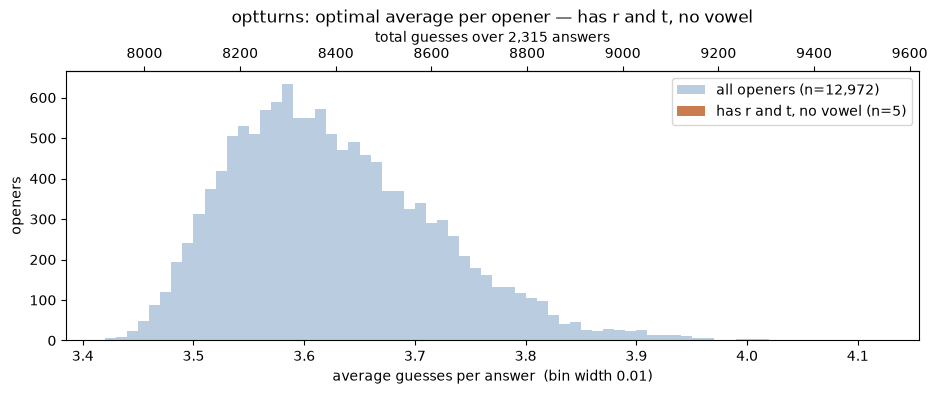

          all openers  n=12,972  mean 3.6259  median 3.6138  best salet 3.4212  worst qajaq 4.1019
has r and t, no vowel  n=     5  mean 3.5944  median 3.5952  best crypt 3.5555  worst tryst 3.6428
                       0.04% of the field, mean -0.0315 guesses against it


,word,total,expected,letters,n_distinct,n_vowels,is_answer
0,crypt,8231,3.555508,"frozenset({r, y, c, t, p})",5,0,True
1,tryps,8273,3.573650,"frozenset({r, y, t, s, p})",5,0,False
2,grypt,8323,3.595248,"frozenset({r, y, t, p, g})",5,0,False
3,crwth,8345,3.604752,"frozenset({r, h, w, c, t})",5,0,False
4,tryst,8433,3.642765,"frozenset({t, s, r, y})",4,0,True


In [19]:
# The subset itself, best first -- everything the plot summarised, word by word.
condition = openers['n_dup'] >= 3
label     = 'three duplicate tiles (two distinct letters)'

plot_openers(condition, label=label)
display(openers[condition].reset_index(drop=True))